# Paso 6 — Caracterización de clases latentes por factores del EFA

**Objetivo:** Describir cada clase latente en términos de las variables latentes identificadas por el EFA.

**Inputs:**
- `dataset_lca_clases.csv` — clases asignadas a cada estudiante
- `efa_cargas_factoriales.csv` — cargas factoriales por ítem
- `dataset_filtrado.csv` — valores originales de los ítems

**Output:**
- `tabla_perfiles_clases.csv` — tabla de perfiles para el artículo
- `tabla_contexto_clases.csv` — distribución de contexto por clase

## 0. Configuración

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

# Nombres interpretativos de cada factor (basados en el codebook PISA 2022)
# Formato: "codigo_factor" : "nombre_interpretativo"
NOMBRES_FACTORES = {
    # Student block — rural
    "F1_estudiante" : "Household socioeconomic resources",
    "F2_estudiante" : "Academic motivation and self-concept",
    "F3_estudiante" : "Household resources (country-specific items)",
    "F4_estudiante" : "School safety and sense of belonging",
    "F5_estudiante" : "School victimization and insecurity",
    "F6_estudiante" : "Support for mathematics learning",
    "F7_estudiante" : "Participation in school creative activities",
    "F8_estudiante" : "Parents' educational attainment",
    "F9_estudiante" : "Beliefs about academic ability",
    "F10_estudiante": "Teacher support for learning",

    # School_b block
    "F1_escuela_b"  : "Professional development of mathematics teachers",
    "F2_escuela_b"  : "Impact of teacher evaluation",
    "F3_escuela_b"  : "Mathematics curriculum planning",
    "F4_escuela_b"  : "School policies for the use of digital technologies",
    "F5_escuela_b"  : "Qualifications of part-time mathematics teachers",
    "F6_escuela_b"  : "School management for student development",

    # School_c block
    "F1_escuela_c"  : "School management and governance",
    "F2_escuela_c"  : "Institutional readiness for remote education",
    "F3_escuela_c"  : "Students' creativity and creative potential",
    "F4_escuela_c"  : "Use of external assessments for school improvement",
    "F5_escuela_c"  : "Educational conditions and response during COVID-19 school closures",
    "F6_escuela_c"  : "School creativity climate",

    # Finance block
    "F1_finanzas"   : "Financial and digital literacy",
    "F2_finanzas"   : "Financial education content",
    "F3_finanzas"   : "Financial attitudes and behaviors",
    "F4_finanzas"   : "Use of digital financial services",
    "F5_finanzas"   : "Basic financial concepts learned at school",
    "F6_finanzas"   : "Financial education activities",
    "F7_finanzas"   : "Family financial socialization",
    "F8_finanzas"   : "Exposure to financial education at school",

    # Other block
    "F1_otros"      : "Student educational trajectory",
}

# Factores a DESCARTAR (variables de diseño, no sustantivas)
FACTORES_DESCARTAR = ["F2_otros", "F3_otros", "F4_otros", "F5_otros"]

# Bloques por factor — sin escuela_a
FACTORES_POR_BLOQUE = {
    "estudiante" : [f"F{i}_estudiante" for i in range(1, 11)],
    "escuela_b"  : [f"F{i}_escuela_b"  for i in range(1, 7)],
    "escuela_c"  : [f"F{i}_escuela_c"  for i in range(1, 7)],
    "finanzas"   : [f"F{i}_finanzas"   for i in range(1, 9)],
    "otros"      : ["F1_otros"],
}

# Etiquetas de clase rural ordenadas por rendimiento
etiquetas_clase = {
    2: "Clase 1 — Rendimiento destacado",
    0: "Clase 2 — Rendimiento medio",
    1: "Clase 3 — Rendimiento medio-bajo",
    3: "Clase 4 — Rendimiento bajo",
}
orden_rendimiento = [2, 0, 1, 3]

print(f"Factores a interpretar : {len(NOMBRES_FACTORES)}")
print(f"Factores descartados   : {len(FACTORES_DESCARTAR)}")

Factores a interpretar : 31
Factores descartados   : 4


## 1. Cargar datos

In [ ]:
df_lca     = pd.read_csv("/workspace/data/output/2022/rural/dataset_lca_clases.csv", low_memory=False)
df_cargas  = pd.read_csv("/workspace/data/output/2022/rural/efa_cargas_factoriales.csv", index_col=0)
df_filtrado = pd.read_csv("/workspace/data/output/2022/rural/dataset_filtrado.csv", low_memory=False)
df_raw     = pd.read_csv("/workspace/data/collection_peru_csv/data_merge/COLLECT_COMP_PERU.csv", low_memory=False)

# "/workspace/data/ouputs/dataset_irt_items_finales.csv"

print(f"LCA clases  : {df_lca.shape}")
print(f"Cargas EFA  : {df_cargas.shape}")
print(f"Filtrado    : {df_filtrado.shape}")
print(f"Raw         : {df_raw.shape}")

N_CLASES = df_lca["clase_lca"].nunique()
print(f"\nNúmero de clases: {N_CLASES}")

LCA clases  : (3720, 135)
Cargas EFA  : (473, 38)
Filtrado    : (3720, 573)
Raw         : (6968, 7147)

Número de clases: 4


## 2. Calcular puntuación de cada estudiante en cada factor

Para cada factor: promedio ponderado por carga de los ítems que lo componen.
Luego estandarizar (z-score) para que todos los factores sean comparables.

In [4]:
# Columnas de factores disponibles en df_cargas
cols_factores = [c for c in df_cargas.columns
                 if c.startswith("F") and c in NOMBRES_FACTORES
                 and c not in FACTORES_DESCARTAR]

print(f"Factores a procesar: {len(cols_factores)}")

df_scores = pd.DataFrame(index=df_filtrado.index)

for factor in cols_factores:
    if factor not in df_cargas.columns:
        continue

    # Ítems que cargan en este factor (carga absoluta >= 0.30)
    cargas_factor = df_cargas[factor].dropna()
    items_factor  = cargas_factor[cargas_factor.abs() >= 0.30].index.tolist()

    # Solo ítems que existen en el dataset filtrado
    items_disponibles = [i for i in items_factor if i in df_filtrado.columns]

    if len(items_disponibles) == 0:
        continue

    # Puntuación = promedio ponderado por carga absoluta
    pesos = cargas_factor[items_disponibles].abs()
    datos = df_filtrado[items_disponibles]

    # Imputar missing con mediana antes de calcular score
    datos_imp = datos.apply(lambda col: col.fillna(col.median()))

    score = (datos_imp * pesos).sum(axis=1) / pesos.sum()
    df_scores[factor] = score

# Estandarizar todos los scores (z-score)
df_scores_z = (df_scores - df_scores.mean()) / df_scores.std()

print(f"Scores calculados para {df_scores_z.shape[1]} factores")
print(f"Shape: {df_scores_z.shape}")

Factores a procesar: 31
Scores calculados para 31 factores
Shape: (3720, 31)


## 3. Calcular perfil promedio por clase latente

In [5]:
# Agregar clase al dataframe de scores
df_scores_z["clase_lca"]        = df_lca["clase_lca"].values
df_scores_z["score_rendimiento"] = df_lca["score_rendimiento"].values

# Promedio de cada factor por clase
factores_cols = [c for c in df_scores_z.columns
                 if c.startswith("F") and c in NOMBRES_FACTORES]

df_perfil = df_scores_z.groupby("clase_lca")[factores_cols].mean().round(3)

# Ordenar clases por rendimiento de mayor a menor
orden_rendimiento = (
    df_scores_z.groupby("clase_lca")["score_rendimiento"]
    .mean()
    .sort_values(ascending=False)
    .index.tolist()
)
df_perfil = df_perfil.loc[orden_rendimiento]

# Renombrar columnas
df_perfil_named = df_perfil.rename(columns=NOMBRES_FACTORES)

# Etiquetas en orden: el primero de orden_rendimiento es el de mayor rendimiento
etiquetas_clase = {
    orden_rendimiento[0]: "Clase 1 — Rendimiento destacado",
    orden_rendimiento[1]: "Clase 2 — Rendimiento medio",
    orden_rendimiento[2]: "Clase 3 — Rendimiento medio-bajo",
    orden_rendimiento[3]: "Clase 4 — Rendimiento bajo",
}

df_perfil_named.index = [etiquetas_clase[i] for i in df_perfil_named.index]

print("Perfil de clases calculado.")
print(f"Shape: {df_perfil_named.shape}  (clases x factores)")
print(f"\nOrden de clases por rendimiento (ID interno → etiqueta):")
for id_clase, etiqueta in etiquetas_clase.items():
    media = df_scores_z.groupby("clase_lca")["score_rendimiento"].mean()[id_clase]
    print(f"  ID {id_clase} → {etiqueta} ({media:.1f} pts)")

Perfil de clases calculado.
Shape: (4, 31)  (clases x factores)

Orden de clases por rendimiento (ID interno → etiqueta):
  ID 2 → Clase 1 — Rendimiento destacado (446.2 pts)
  ID 0 → Clase 2 — Rendimiento medio (398.3 pts)
  ID 1 → Clase 3 — Rendimiento medio-bajo (382.2 pts)
  ID 3 → Clase 4 — Rendimiento bajo (354.7 pts)


## 4. Heatmap de perfiles — tabla principal del artículo

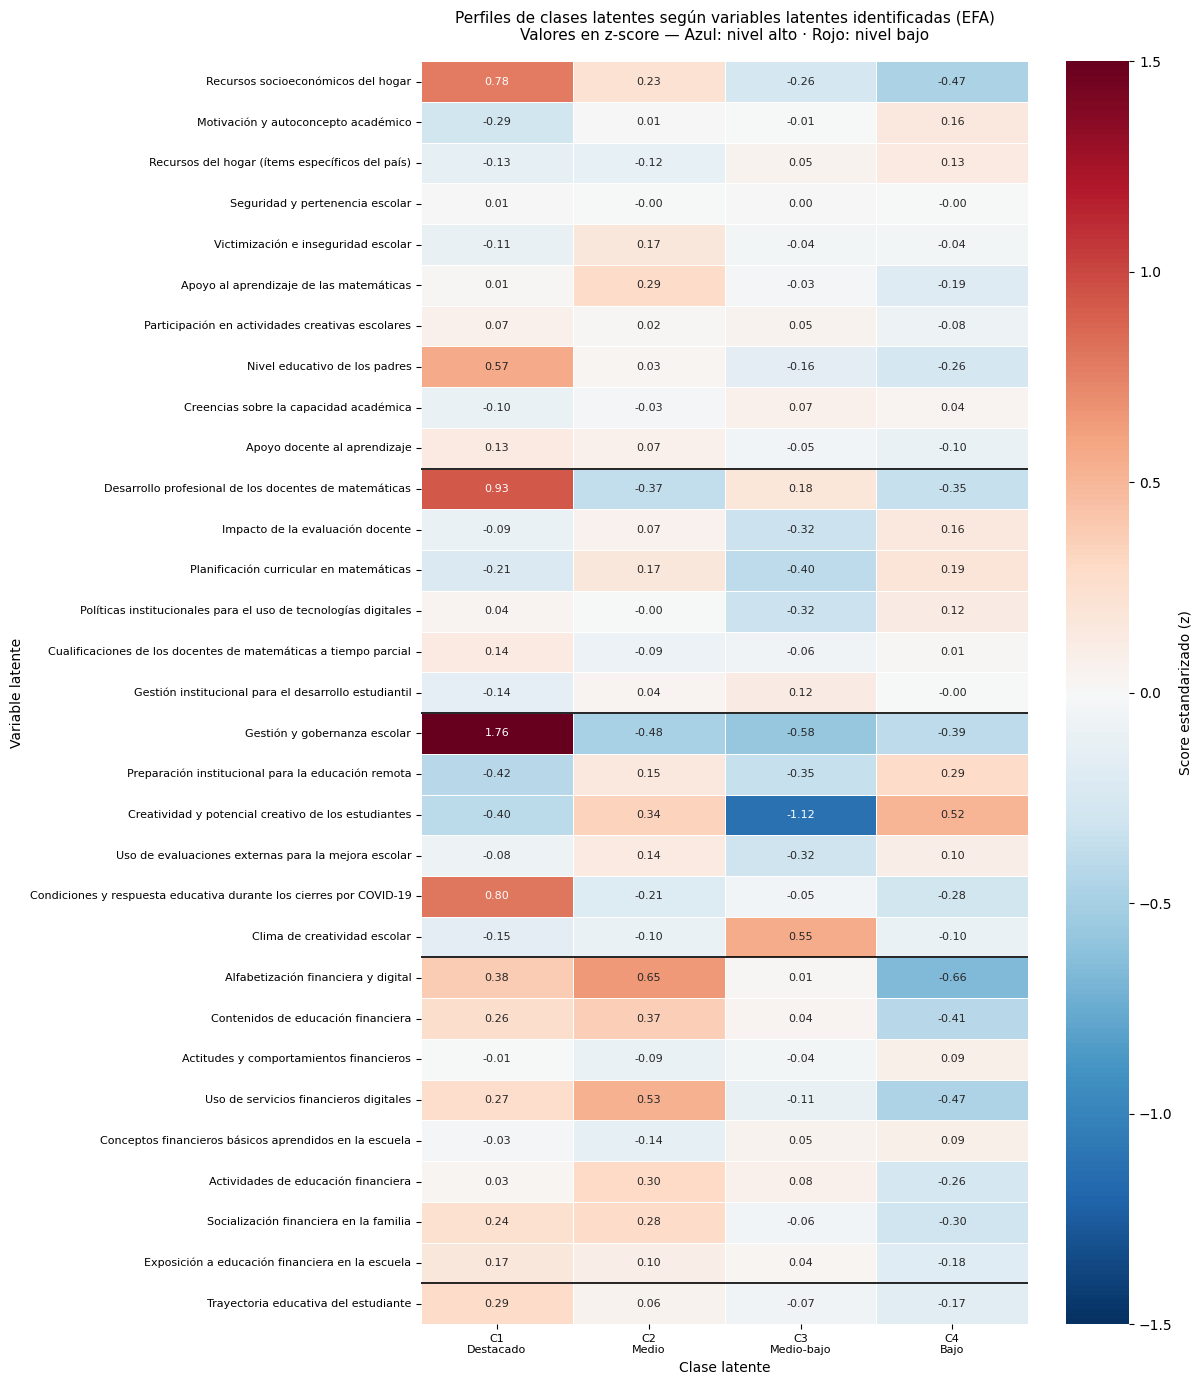

Guardado: figura_perfiles_clases_latentes.png


In [6]:
# Transponer para que factores sean filas y clases columnas
df_plot = df_perfil_named.T

# Abreviar nombres de clases para el gráfico
df_plot.columns = [
    "C1\nDestacado", "C2\nMedio", "C3\nMedio-bajo", "C4\nBajo"
]

altura = max(10, len(df_plot) * 0.45)
fig, ax = plt.subplots(figsize=(12, altura))

sns.heatmap(
    df_plot,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1.5,
    vmax=1.5,
    linewidths=0.4,
    linecolor="white",
    ax=ax,
    annot_kws={"size": 8},
    cbar_kws={"label": "Score estandarizado (z)"},
)

ax.set_title(
    "Perfiles de clases latentes según variables latentes identificadas (EFA)\n"
    "Valores en z-score — Azul: nivel alto · Rojo: nivel bajo",
    fontsize=11, pad=15
)
ax.set_xlabel("Clase latente", fontsize=10)
ax.set_ylabel("Variable latente", fontsize=10)
ax.tick_params(axis="y", labelsize=8)
ax.tick_params(axis="x", labelsize=8)

# Separadores visuales por bloque
bloques = {
    "Estudiante": len([f for f in factores_cols if "estudiante" in f]),
    # "Escuela A" : len([f for f in factores_cols if "escuela_a" in f]),
    "Escuela B" : len([f for f in factores_cols if "escuela_b" in f]),
    "Escuela C" : len([f for f in factores_cols if "escuela_c" in f]),
    "Finanzas"  : len([f for f in factores_cols if "finanzas" in f]),
    "Otros"     : len([f for f in factores_cols if "otros" in f]),
}
pos = 0
for nombre_bloque, n in bloques.items():
    if n > 0 and pos > 0:
        ax.axhline(pos, color="black", linewidth=1.2)
    pos += n

plt.tight_layout()
plt.savefig("/workspace/data/img_report_rural/figura_perfiles_clases_latentes.png", dpi=150, bbox_inches="tight")
plt.show()
print("Guardado: figura_perfiles_clases_latentes.png")

## 5. Variables latentes más discriminantes entre clases

Identificar qué factores tienen mayor varianza entre clases — los más importantes para explicar el rendimiento.

In [ ]:
from scipy import stats

resultados_anova = []

for factor in factores_cols:
    grupos = [
        df_scores_z[df_scores_z["clase_lca"] == k][factor].dropna()
        for k in sorted(df_scores_z["clase_lca"].unique())
    ]
    try:
        f_stat, p_val = stats.f_oneway(*grupos)
        # Eta-cuadrado como medida de tamaño del efecto
        medias = [g.mean() for g in grupos]
        rango  = max(medias) - min(medias)
        resultados_anova.append({
            "factor"        : factor,
            "nombre"        : NOMBRES_FACTORES.get(factor, factor),
            "F"             : round(f_stat, 2),
            "p_valor"       : round(p_val, 4),
            "rango_medias"  : round(rango, 3),
        })
    except:
        pass

df_anova = pd.DataFrame(resultados_anova).sort_values("F", ascending=False)

print("Top 15 variables latentes más discriminantes entre clases (ANOVA):")
print("═" * 75)
print(f"  {'Variable latente':<45} {'F':>8} {'p':>8} {'Rango':>8}")
print("═" * 75)
for _, fila in df_anova.head(15).iterrows():
    sig = "***" if fila["p_valor"] < 0.001 else "**" if fila["p_valor"] < 0.01 else "*"
    print(f"  {fila['nombre'][:44]:<45} {fila['F']:>8.1f} {sig:>8} {fila['rango_medias']:>8.3f}")
print("═" * 75)
print("*** p<0.001  ** p<0.01  * p<0.05")

Top 15 variables latentes más discriminantes entre clases (ANOVA):
═══════════════════════════════════════════════════════════════════════════
  Variable latente                                     F        p    Rango
═══════════════════════════════════════════════════════════════════════════
  Gestión y gobernanza escolar                    5430.0      ***    2.342
  Creatividad y potencial creativo de los estu     754.5      ***    1.641
  Alfabetización financiera y digital              516.8      ***    1.304
  Desarrollo profesional de los docentes de ma     446.8      ***    1.302
  Recursos socioeconómicos del hogar               373.0      ***    1.246
  Condiciones y respuesta educativa durante lo     258.0      ***    1.081
  Uso de servicios financieros digitales           252.4      ***    0.998
  Contenidos de educación financiera               154.5      ***    0.779
  Nivel educativo de los padres                    132.5      ***    0.829
  Preparación institucional par

In [9]:
print("Top 15 variables latentes más discriminantes entre clases (ANOVA):")
print(df_anova.head(15)[["nombre", "F", "p_valor", "rango_medias"]].to_string())

Top 15 variables latentes más discriminantes entre clases (ANOVA):
                                                                nombre        F  p_valor  rango_medias
16                                        Gestión y gobernanza escolar  5430.00      0.0         2.342
18                 Creatividad y potencial creativo de los estudiantes   754.48      0.0         1.641
22                                 Alfabetización financiera y digital   516.80      0.0         1.304
10               Desarrollo profesional de los docentes de matemáticas   446.78      0.0         1.302
0                                   Recursos socioeconómicos del hogar   372.97      0.0         1.246
20  Condiciones y respuesta educativa durante los cierres por COVID-19   258.01      0.0         1.081
25                              Uso de servicios financieros digitales   252.39      0.0         0.998
23                                  Contenidos de educación financiera   154.52      0.0         0.779
7     

In [10]:
# Ver tabla de perfiles en números
print("\nTabla de perfiles por clase (z-scores):")
print(df_perfil_named.round(2).to_string())


Tabla de perfiles por clase (z-scores):
                                  Recursos socioeconómicos del hogar  Motivación y autoconcepto académico  Recursos del hogar (ítems específicos del país)  Seguridad y pertenencia escolar  Victimización e inseguridad escolar  Apoyo al aprendizaje de las matemáticas  Participación en actividades creativas escolares  Nivel educativo de los padres  Creencias sobre la capacidad académica  Apoyo docente al aprendizaje  Desarrollo profesional de los docentes de matemáticas  Impacto de la evaluación docente  Planificación curricular en matemáticas  Políticas institucionales para el uso de tecnologías digitales  Cualificaciones de los docentes de matemáticas a tiempo parcial  Gestión institucional para el desarrollo estudiantil  Gestión y gobernanza escolar  Preparación institucional para la educación remota  Creatividad y potencial creativo de los estudiantes  Uso de evaluaciones externas para la mejora escolar  Condiciones y respuesta educativa durant

## 6. Enriquecer con variables de contexto

In [11]:
# Filtrar df_raw a zona rural
zonas_rurales = [
    "A village, hamlet or rural area (fewer than 3 000 people)",
    "A small town (3 000 to about 15 000 people)"
]
df_raw_rural = df_raw[df_raw["SC001Q01TA"].isin(zonas_rurales)].copy()
df_raw_rural = df_raw_rural.reset_index(drop=True)

print(f"df_raw_rural: {len(df_raw_rural):,} filas")
print(f"df_lca      : {len(df_lca):,} filas")

# Asignar variables de contexto
df_lca["tipo_escuela"] = df_raw_rural["SC013Q01TA"].apply(
    lambda x: "Publica" if isinstance(x, str) and "public" in x.lower() else "Privada"
).values

df_lca["tipo_comunidad"] = df_raw_rural["SC001Q01TA"].apply(
    lambda x: "Rural" if "rural" in str(x).lower() or "village" in str(x).lower()
    else "Pueblo pequeno"
).values

# Crear etiqueta de clase — esto faltaba
etiquetas_clase = {
    2: "Clase 1 — Rendimiento destacado",
    0: "Clase 2 — Rendimiento medio",
    1: "Clase 3 — Rendimiento medio-bajo",
    3: "Clase 4 — Rendimiento bajo",
}
df_lca["clase_label"] = df_lca["clase_lca"].map(etiquetas_clase)

# Orden para las tablas
orden_etiquetas = [
    "Clase 1 — Rendimiento destacado",
    "Clase 2 — Rendimiento medio",
    "Clase 3 — Rendimiento medio-bajo",
    "Clase 4 — Rendimiento bajo",
]

# Tabla escuela por clase
tabla_escuela = pd.crosstab(
    df_lca["clase_label"],
    df_lca["tipo_escuela"],
    normalize="index"
).round(3) * 100
tabla_escuela = tabla_escuela.loc[orden_etiquetas]

print("\nTipo de escuela por clase latente (%):")
print(tabla_escuela.to_string())

# Tabla comunidad por clase
tabla_comunidad = pd.crosstab(
    df_lca["clase_label"],
    df_lca["tipo_comunidad"],
    normalize="index"
).round(3) * 100
tabla_comunidad = tabla_comunidad.loc[orden_etiquetas]

print("\nTipo de comunidad por clase latente (%):")
print(tabla_comunidad.to_string())

df_raw_rural: 3,720 filas
df_lca      : 3,720 filas

Tipo de escuela por clase latente (%):
tipo_escuela                      Privada  Publica
clase_label                                       
Clase 1 — Rendimiento destacado      93.5      6.5
Clase 2 — Rendimiento medio           0.0    100.0
Clase 3 — Rendimiento medio-bajo      0.0    100.0
Clase 4 — Rendimiento bajo            0.0    100.0

Tipo de comunidad por clase latente (%):
tipo_comunidad                    Pueblo pequeno  Rural
clase_label                                            
Clase 1 — Rendimiento destacado             53.3   46.7
Clase 2 — Rendimiento medio                 62.5   37.5
Clase 3 — Rendimiento medio-bajo            41.2   58.8
Clase 4 — Rendimiento bajo                  45.7   54.3


## 8. Guardar tablas para el artículo

In [20]:
# Tabla principal de perfiles
df_perfil_named.T.to_csv("/workspace/data/output_rural/tabla_perfiles_clases.csv")
print("Guardado: tabla_perfiles_clases.csv")

# Tabla de contexto
tabla_comunidad.to_csv("/workspace/data/output_rural/tabla_contexto_comunidad.csv")
tabla_escuela.to_csv("/workspace/data/output_rural/tabla_contexto_escuela.csv")
print("Guardado: tabla_contexto_comunidad.csv")
print("Guardado: tabla_contexto_escuela.csv")

# Ranking de variables latentes discriminantes
df_anova.to_csv("/workspace/data/output_rural/tabla_anova_factores.csv", index=False)
print("Guardado: tabla_anova_factores.csv")

print("\n✓ Paso 6 completado.")
print("Siguiente paso: redactar sección de resultados del artículo en inglés.")

Guardado: tabla_perfiles_clases.csv
Guardado: tabla_contexto_comunidad.csv
Guardado: tabla_contexto_escuela.csv
Guardado: tabla_anova_factores.csv

✓ Paso 6 completado.
Siguiente paso: redactar sección de resultados del artículo en inglés.
